In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import os

In [13]:
CLEAN_PATH = "../data/processed/cleaned_rainfall.csv"
df = pd.read_csv(CLEAN_PATH)
os.makedirs("../reports/figures", exist_ok=True)
print(df.describe())

              YEAR          JAN          FEB          MAR          APR  \
count  4116.000000  4116.000000  4116.000000  4116.000000  4116.000000   
mean   1958.218659    18.944728    21.794315    27.330685    43.100777   
std      33.140898    33.571472    35.898711    46.931111    67.803579   
min    1901.000000     0.000000     0.000000     0.000000     0.000000   
25%    1930.000000     0.600000     0.600000     1.000000     3.000000   
50%    1958.000000     6.000000     6.700000     7.800000    15.700000   
75%    1987.000000    22.125000    26.800000    31.225000    49.825000   
max    2015.000000   583.700000   403.500000   605.600000   595.100000   

               MAY          JUN          JUL          AUG          SEP  \
count  4116.000000  4116.000000  4116.000000  4116.000000  4116.000000   
mean     85.709597   230.123251   347.108188   290.233503   197.327721   
std     123.197115   234.589793   269.322595   188.681158   135.312552   
min       0.000000     0.400000     0

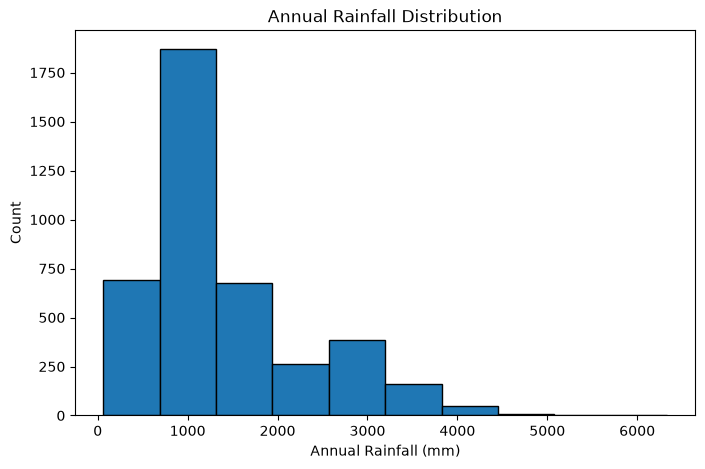

In [14]:
plt.figure(figsize=(8,5))
plt.hist(df["ANNUAL"], edgecolor="black")
plt.title("Annual Rainfall Distribution")
plt.xlabel("Annual Rainfall (mm)")
plt.ylabel("Count")
plt.show()
plt.savefig("../reports/figures/01_annual_dist.png")
plt.close()

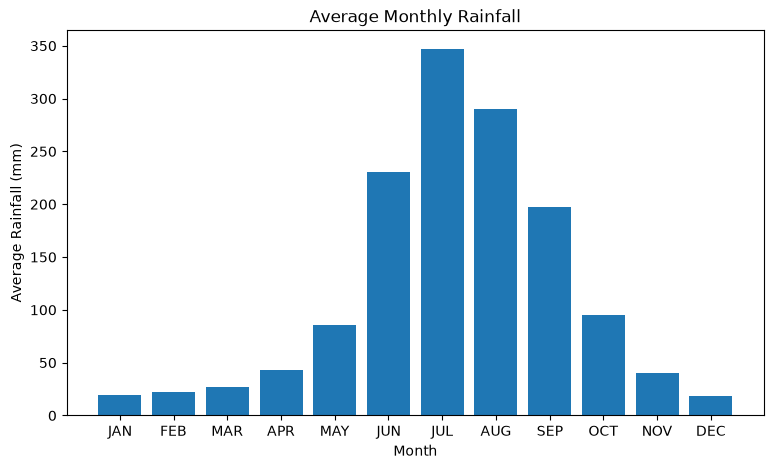

In [15]:
monthly = ['JAN','FEB','MAR','APR','MAY','JUN','JUL','AUG','SEP','OCT','NOV','DEC']
plt.figure(figsize=(9,5))
plt.bar(monthly, df[monthly].mean())
plt.title("Average Monthly Rainfall")
plt.xlabel("Month")
plt.ylabel("Average Rainfall (mm)")
plt.show()
plt.savefig("../reports/figures/02_monthly_avg.png"); plt.close()

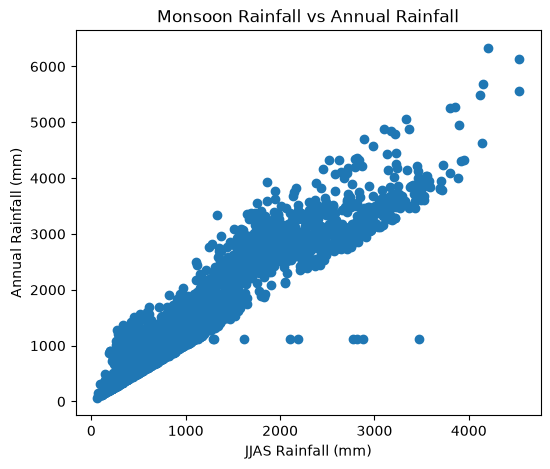

In [16]:
plt.figure(figsize=(6, 5))
plt.scatter(df["JJAS"], df["ANNUAL"])
plt.title("Monsoon Rainfall vs Annual Rainfall")
plt.xlabel("JJAS Rainfall (mm)")
plt.ylabel("Annual Rainfall (mm)")
plt.show()
plt.savefig("../reports/figures/03_jjas_vs_annual.png", dpi=150); plt.close()

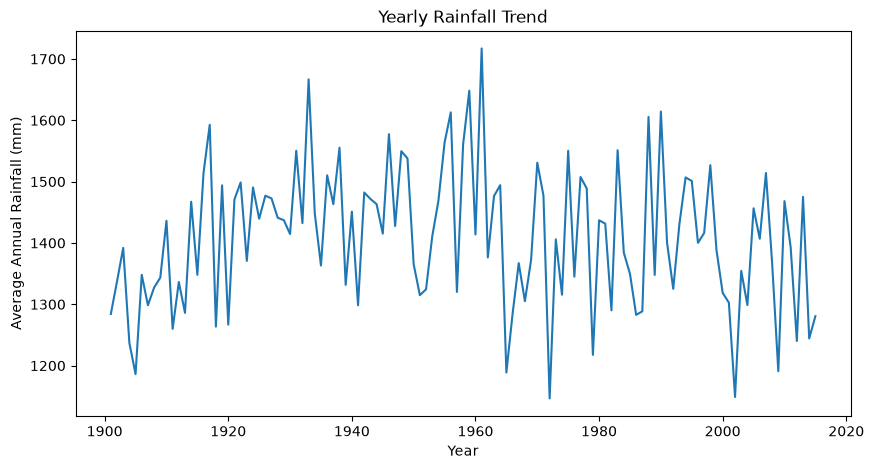

In [17]:
yearly = df.groupby("YEAR")["ANNUAL"].mean()
plt.figure(figsize=(10,5))
plt.plot(yearly.index, yearly.values)
plt.title("Yearly Rainfall Trend")
plt.xlabel("Year")
plt.ylabel("Average Annual Rainfall (mm)")
plt.show()

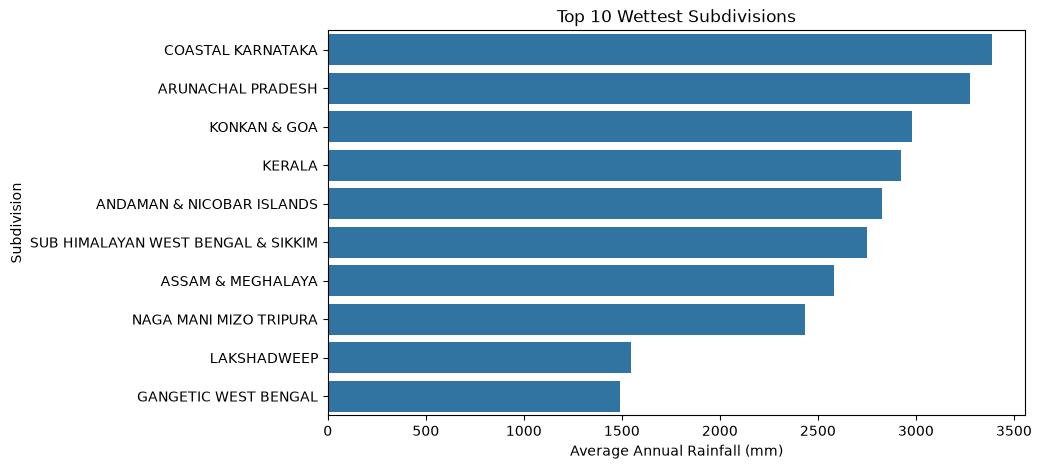

In [18]:
top = df.groupby("SUBDIVISION")["ANNUAL"].mean().nlargest(10)
plt.figure(figsize=(9,5))
sns.barplot(x=top.values, y=top.index)
plt.title("Top 10 Wettest Subdivisions")
plt.xlabel("Average Annual Rainfall (mm)")
plt.ylabel("Subdivision")
plt.show()
plt.savefig("../reports/figures/05_top_subdivisions.png")
plt.close()

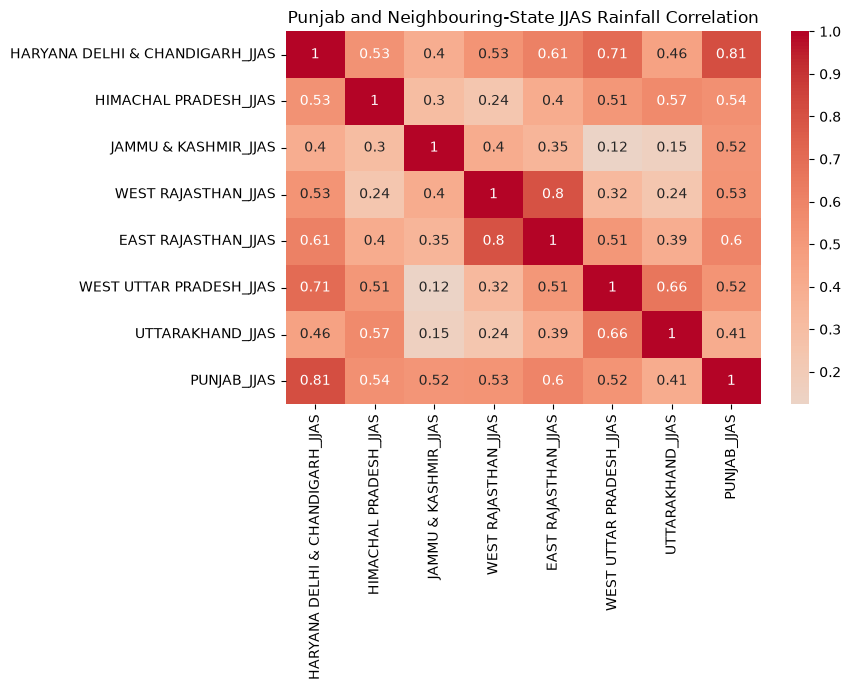

In [22]:
rain = pd.read_csv("../data/processed/punjab_dataset.csv")
features = [c for c in rain.columns if "_JJAS" in c and "PUNJAB" not in c]
columns = features + ["PUNJAB_JJAS"]

plt.figure(figsize=(9, 7))
sns.heatmap(rain[columns].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Punjab and Neighbouring-State JJAS Rainfall Correlation")
plt.tight_layout()
plt.show()
plt.savefig("../reports/figures/06_punjab_correlation.png")
plt.close()